# CRPT Simulation Control

Control the Cartesian Robot Plate Transporter through its local browser simulator. Simulation mode ignores COM and never commands physical hardware. Run cells from top to bottom; controller connection starts the simulator view if it is not already running.

## 1. Import and Initialize Simulation API

Import the controller, notebook display and widget tools, plotting, and logging helpers. The project root is added to Python's import path so this notebook can run from the workspace.

In [6]:
from pathlib import Path
import importlib
import logging
import math
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "robot_client").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "robot_client").is_dir():
    raise RuntimeError("Open this notebook from the CRPT workspace so robot_client can be found")
sys.path.insert(0, str(PROJECT_ROOT))

import robot_client.config as config
import robot_client.coordinates as coordinates_module
import robot_client.simulation.simulator as simulator_module
import robot_client.robot as robot_module

importlib.reload(config)
importlib.reload(coordinates_module)
importlib.reload(simulator_module)
importlib.reload(robot_module)
from robot_client.coordinates import local_to_machine_axes
from robot_client.robot import RobotController

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("crpt.notebook")

SIMULATOR_URL = "http://127.0.0.1:8765"
FEED_XY_MM_MIN = config.DEFAULT_FEED_RATE_XY
FEED_Z_MM_MIN = config.DEFAULT_FEED_RATE_Z
ARM_REACH_MM = config.ARM_REACH_MM
print(f"CRPT simulation tools loaded · arm reach {ARM_REACH_MM:.0f} mm · A limit {config.A_AXIS_LIMIT_DEG:.0f}°")

CRPT simulation tools loaded · arm reach 300 mm · A limit 360°


## 2. Connect to Robot Instance in Simulator

`sim=True` selects the simulator package in `robot_client/simulation/`, ignores COM, and starts or attaches to its local browser server. To launch the view separately, run `python -m robot_client.simulation`. Simulation always uses ideal zero-degree homing correction.

In [15]:
if "robot" in globals():
    robot.close()

robot = RobotController(
    sim=True,
    simulator_url=SIMULATOR_URL,
    open_simulator=True,
    homing_rotation_offset_deg=0.0,
).connect()

initial_status = robot.link.get_status()
print("Simulator connected:", robot.link.url)
print("Effective homing correction:", robot.homing_rotation_offset_deg, "degrees")
print("Orientation:", robot.orientation)
print("Machine position X,Y,Z,A:", robot.machine_position)
print("Allowed machine-axis bounds:", robot.axis_bounds)
print("GRBL-CRPT settings loaded:", len(robot.settings), "settings")

Simulator connected: http://127.0.0.1:8765
Effective homing correction: 0.0 degrees
Orientation: 1
Machine position X,Y,Z,A: [170.0, 470.0, 470.0, 0.0]
Allowed machine-axis bounds: {'x': (0.0, 470.0), 'y': (0.0, 470.0), 'z': (0.0, 470.0), 'a': (0.0, 360.0)}
GRBL-CRPT settings loaded: 9 settings


## 3. Define Workspace, Home Pose, and Safety Limits

Homing leaves machine X/Y at `(0, 0)`, raises Z to its safe maximum, and faces side 1 (+X). A is limited to 360 degrees. Local side coordinates `(X', Y')` map to machine coordinates using arm reach `L` and maximum travels `MTX`, `MTY`:

- Side 1 (+X): `X = Y' + MTX - L`, `Y = MTY - X'`
- Side 2 (+Y): `X = X'`, `Y = Y' + MTY - L`
- Side 3 (-X): `X = L - Y'`, `Y = X'`
- Side 4 (-Y): `X = MTX - X'`, `Y = L - Y'`

The following guards use pull-back-aware bounds before sending transformed targets to the controller.

In [16]:
TRAVEL_MM = {"x": robot.settings[130], "y": robot.settings[131], "z": robot.settings[132]}
SAFE_BOUNDS = dict(robot.axis_bounds)
SAFE_Z_MM = SAFE_BOUNDS["z"][1]
MAPPING_TRAVEL_MM = {
    "x": SAFE_BOUNDS["x"][1],
    "y": SAFE_BOUNDS["y"][1],
}
HOME_POSE = {
    "x": robot.machine_position[0],
    "y": robot.machine_position[1],
    "z": robot.machine_position[2],
    "a": robot.machine_position[3],
    "orientation": robot.orientation,
}
DEFAULT_FEED_RATES = {"xy_mm_min": FEED_XY_MM_MIN, "z_mm_min": FEED_Z_MM_MIN}
ACCELERATION_MM_S2 = None  # Acceleration remains controlled by GRBL-CRPT firmware settings.


def validate_side_target(side, x=None, y=None, z=None):
    """Validate side-space XY and machine-space Z before issuing a move."""
    machine_xy = local_to_machine_axes(
        side,
        x=x,
        y=y,
        axis_bounds=robot.axis_bounds,
        machine_travel=MAPPING_TRAVEL_MM,
    )
    if z is not None:
        lower_z, upper_z = SAFE_BOUNDS["z"]
        if not lower_z <= z <= upper_z:
            raise ValueError(f"Z={z} mm is outside safe range [{lower_z}, {upper_z}]")
    return machine_xy


print("Home machine pose:", HOME_POSE)
print("Safe travel bounds:", SAFE_BOUNDS)
print("Side-mapping max travel:", MAPPING_TRAVEL_MM)
print("Default feed rates:", DEFAULT_FEED_RATES)
print("Acceleration: controlled by GRBL-CRPT, not overridden by this client")

Home machine pose: {'x': 170.0, 'y': 470.0, 'z': 470.0, 'a': 0.0, 'orientation': 1}
Safe travel bounds: {'x': (0.0, 470.0), 'y': (0.0, 470.0), 'z': (0.0, 470.0), 'a': (0.0, 360.0)}
Side-mapping max travel: {'x': 470.0, 'y': 470.0}
Default feed rates: {'xy_mm_min': 1500.0, 'z_mm_min': 600.0}
Acceleration: controlled by GRBL-CRPT, not overridden by this client


## 4. Set End-Effector Orientation with `set_orientation`

The presets correspond to +X, +Y, −X, and −Y. The homing correction is applied once after `$H`; subsequent side changes use exact 90-degree cardinal steps and select the nearest A-axis equivalent.

{'machine_xyz_mm': (170.0, 470.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}


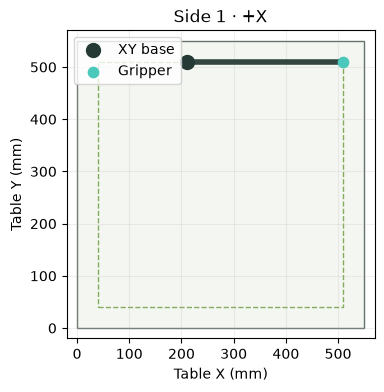

In [9]:
ORIENTATION_PRESETS = {1: "+X", 2: "+Y", 3: "-X", 4: "-Y"}


def pose_summary():
    x, y, z, a = robot.machine_position
    return {
        "machine_xyz_mm": (round(x, 1), round(y, 1), round(z, 1)),
        "a_axis_deg": round(a, 1),
        "side": robot.orientation,
        "facing": ORIENTATION_PRESETS.get(robot.orientation),
    }


def show_pose():
    x, y, z, a = robot.machine_position
    offset = (config.TABLE_SIDE_MM - (TRAVEL_MM["x"] - robot.settings[140])) / 2
    display_x, display_y = x + offset, y + offset
    calibrated_a = a % 360.0
    if not math.isclose(calibrated_a, 0.0, abs_tol=1e-6):
        calibrated_a -= config.ROTATION_OFFSET_DEG
    heading = math.radians(calibrated_a)
    tip_x = display_x + math.cos(heading) * ARM_REACH_MM
    tip_y = display_y + math.sin(heading) * ARM_REACH_MM

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.add_patch(plt.Rectangle((0, 0), config.TABLE_SIDE_MM, config.TABLE_SIDE_MM,
                               facecolor="#f4f6f1", edgecolor="#66736c"))
    ax.add_patch(plt.Rectangle((offset, offset), TRAVEL_MM["x"] - robot.settings[140],
                               TRAVEL_MM["y"] - robot.settings[141], fill=False,
                               edgecolor="#83ad5c", linestyle="--"))
    ax.plot([display_x, tip_x], [display_y, tip_y], color="#33463f", linewidth=4)
    ax.scatter([display_x], [display_y], s=100, color="#263a35", label="XY base", zorder=3)
    ax.scatter([tip_x], [tip_y], s=55, color="#4ac8bb", label="Gripper", zorder=4)
    ax.set(xlim=(-20, config.TABLE_SIDE_MM + 20), ylim=(-20, config.TABLE_SIDE_MM + 20),
           aspect="equal", xlabel="Table X (mm)", ylabel="Table Y (mm)",
           title=f"Side {robot.orientation} · {ORIENTATION_PRESETS.get(robot.orientation)}")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.2)
    plt.show()
    plt.close(fig)


def set_orientation(side):
    """Orient the simulated rod to one of the four cardinal sides."""
    robot.set_orientation(side)
    status = pose_summary()
    print(status)
    return status


set_orientation(1)
show_pose()

## 5. Move Robot with `move` Commands

`move()` accepts absolute side-space targets or relative increments. It validates the transformed X/Y and Z targets, then delegates the actual movement to `robot.move_to()`.

{'machine_xyz_mm': (0.0, 0.0, 450.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}
{'machine_xyz_mm': (0.0, 5.0, 450.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}
{'machine_xyz_mm': (235.0, 235.0, 450.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}


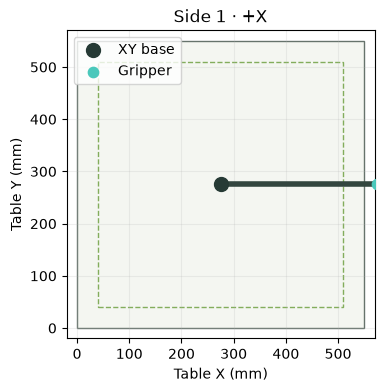

In [ ]:
def _side_xy_from_machine(side):
    machine_x, machine_y = robot.machine_position[:2]
    reach = ARM_REACH_MM
    max_x = MAPPING_TRAVEL_MM["x"]
    max_y = MAPPING_TRAVEL_MM["y"]
    if side == 1:
        return max_y - machine_y, machine_x - (max_x - reach)
    if side == 2:
        return machine_x, machine_y - (max_y - reach)
    if side == 3:
        return machine_y, reach - machine_x
    if side == 4:
        return max_x - machine_x, reach - machine_y
    raise ValueError(f"Unknown side {side}; choose 1, 2, 3, or 4")


def move(x=None, y=None, z=None, *, side=None, relative=False):
    """Move in side-space; optionally interpret supplied axes as increments."""
    target_side = robot.orientation if side is None else side
    if target_side is None:
        target_side = 1
    if robot.orientation != target_side:
        set_orientation(target_side)

    if relative:
        current_x, current_y = _side_xy_from_machine(target_side)
        current_z = robot.machine_position[2]
        x = current_x + x if x is not None else None
        y = current_y + y if y is not None else None
        z = current_z + z if z is not None else None

    validate_side_target(target_side, x=x, y=y, z=z)
    robot.move_to(x=x, y=y, z=z)
    result = pose_summary()
    print(result)
    return result


# Move to a safe local point at the +X home side.
move(z=450)
move(x=40, y=40, z=450, side=1)
show_pose()

## 6. Execute Plate Transfer with `transport`

The example transfers from the +Y pickup table (side 2) to the +X destination table (side 1). `approach_offset_mm` raises the requested pick/place Z for a dry-run approach; leave it at zero for the configured target height. The controller always retracts to `SAFE_Z_MM`; the requested retract clearance is checked before motion.

In [ ]:
SOURCE_SLOT = {"side": 2, "xyz": (235.0, 190.0, 10.0)}
DESTINATION_SLOT = {"side": 1, "xyz": (235.0, 190.0, 10.0)}
APPROACH_OFFSET_MM = 0.0
MIN_RETRACT_CLEARANCE_MM = 20.0


def transport(source_slot, destination_slot, *, approach_offset_mm=0.0,
              minimum_retract_clearance_mm=20.0):
    """Transfer one simulated plate between side-space XYZ targets."""
    if approach_offset_mm < 0 or minimum_retract_clearance_mm < 0:
        raise ValueError("Approach and retract clearances must be non-negative")
    source_xyz = tuple(source_slot["xyz"])
    destination_xyz = tuple(destination_slot["xyz"])
    pick_xyz = (source_xyz[0], source_xyz[1], source_xyz[2] + approach_offset_mm)
    place_xyz = (destination_xyz[0], destination_xyz[1], destination_xyz[2] + approach_offset_mm)

    validate_side_target(source_slot["side"], *pick_xyz)
    validate_side_target(destination_slot["side"], *place_xyz)
    if SAFE_Z_MM - max(pick_xyz[2], place_xyz[2]) < minimum_retract_clearance_mm:
        raise ValueError("Target Z leaves less than the requested safe retract clearance")

    logger.info("Transport side %s -> side %s", source_slot["side"], destination_slot["side"])
    robot.transport(
        from_orientation=source_slot["side"],
        to_orientation=destination_slot["side"],
        pick_xyz=pick_xyz,
        place_xyz=place_xyz,
    )
    result = pose_summary()
    print("Transfer complete:", result)
    return result


transport(
    SOURCE_SLOT,
    DESTINATION_SLOT,
    approach_offset_mm=APPROACH_OFFSET_MM,
    minimum_retract_clearance_mm=MIN_RETRACT_CLEARANCE_MM,
)

2026-10-02 20:33:22,902 INFO Transport side 2 -> side 1


Transfer complete: {'machine_xyz_mm': (360.0, 235.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}


{'machine_xyz_mm': (360.0, 235.0, 470.0),
 'a_axis_deg': 0.0,
 'side': 1,
 'facing': '+X'}

## 7. Build Reusable Motion Routines

These wrappers keep home, guard checks, orientation changes, and transfers consistent across manual cells and the interactive controls.

In [9]:
def go_home():
    """Run the simulator's homing sequence and restore calibrated side 1."""
    robot.home()
    logger.info("Homed: %s", robot.machine_position)
    return pose_summary()


def safe_move(*, side=None, x=None, y=None, z=None, relative=False):
    target_side = robot.orientation if side is None else side
    if target_side is None:
        target_side = 1
    if target_side != robot.orientation:
        set_orientation(target_side)
    if not relative:
        validate_side_target(target_side, x=x, y=y, z=z)
    return move(x=x, y=y, z=z, side=target_side, relative=relative)


def orient_and_move(side, *, x=None, y=None, z=None):
    set_orientation(side)
    return safe_move(side=side, x=x, y=y, z=z)


def transfer_plate(source_slot=SOURCE_SLOT, destination_slot=DESTINATION_SLOT,
                   *, approach_offset_mm=0.0, minimum_retract_clearance_mm=20.0):
    return transport(
        source_slot,
        destination_slot,
        approach_offset_mm=approach_offset_mm,
        minimum_retract_clearance_mm=minimum_retract_clearance_mm,
    )


print("Reusable routines ready: go_home, safe_move, orient_and_move, transfer_plate")

Reusable routines ready: go_home, safe_move, orient_and_move, transfer_plate


## 8. Add Interactive Controls and Live Status Output

Use these controls for one-off commands without editing a code cell. Status refresh reads the latest controller pose; all submitted motion still passes through the notebook safety checks.

In [10]:
orientation_control = widgets.Dropdown(
    options=[(f"Side {side} · {name}", side) for side, name in ORIENTATION_PRESETS.items()],
    value=1,
    description="Side:",
)
orient_button = widgets.Button(description="Set orientation", button_style="info")
status_button = widgets.Button(description="Refresh status", icon="refresh")
orientation_output = widgets.Output()
status_output = widgets.Output()

move_side_control = widgets.Dropdown(options=list(ORIENTATION_PRESETS), value=1, description="Side:")
move_mode_control = widgets.ToggleButtons(options=[("Absolute", False), ("Relative jog", True)], value=False)
move_x_control = widgets.FloatText(value=235.0, description="X (mm):")
move_y_control = widgets.FloatText(value=160.0, description="Y (mm):")
move_z_control = widgets.FloatText(value=450.0, description="Z (mm):")
move_button = widgets.Button(description="Move", button_style="success", icon="location-arrow")
move_output = widgets.Output()

source_side_control = widgets.Dropdown(options=list(ORIENTATION_PRESETS), value=2, description="From:")
destination_side_control = widgets.Dropdown(options=list(ORIENTATION_PRESETS), value=1, description="To:")
source_xyz_controls = [widgets.FloatText(value=value, description=label, layout=widgets.Layout(width="170px"))
                       for value, label in zip(SOURCE_SLOT["xyz"], ("Pick X", "Pick Y", "Pick Z"))]
destination_xyz_controls = [widgets.FloatText(value=value, description=label, layout=widgets.Layout(width="170px"))
                            for value, label in zip(DESTINATION_SLOT["xyz"], ("Place X", "Place Y", "Place Z"))]
approach_control = widgets.FloatText(value=0.0, description="Approach +Z:")
retract_control = widgets.FloatText(value=20.0, description="Min retract:")
transfer_button = widgets.Button(description="Transfer plate", button_style="warning", icon="play")
transfer_output = widgets.Output()


def _show_in(output, action):
    with output:
        clear_output(wait=True)
        try:
            action()
        except Exception as error:
            logger.exception("Notebook control failed")
            print(f"Command rejected: {error}")


def _on_orient(_):
    _show_in(orientation_output, lambda: display(set_orientation(orientation_control.value)))


def _on_status(_):
    def refresh_status():
        robot._update_machine_position(robot.link.get_status())
        print("GRBL-CRPT status:", robot.link.get_status())
        print("Pose:", pose_summary())
        show_pose()
    _show_in(status_output, refresh_status)


def _on_move(_):
    def issue_move():
        display(safe_move(
            side=move_side_control.value,
            x=move_x_control.value,
            y=move_y_control.value,
            z=move_z_control.value,
            relative=move_mode_control.value,
        ))
        show_pose()
    _show_in(move_output, issue_move)


def _on_transfer(_):
    source = {"side": source_side_control.value, "xyz": tuple(field.value for field in source_xyz_controls)}
    destination = {"side": destination_side_control.value,
                  "xyz": tuple(field.value for field in destination_xyz_controls)}
    _show_in(transfer_output, lambda: display(transfer_plate(
        source, destination,
        approach_offset_mm=approach_control.value,
        minimum_retract_clearance_mm=retract_control.value,
    )))


orient_button.on_click(_on_orient)
status_button.on_click(_on_status)
move_button.on_click(_on_move)
transfer_button.on_click(_on_transfer)

display(widgets.VBox([
    widgets.HBox([orientation_control, orient_button, status_button]),
    orientation_output,
    status_output,
    widgets.HTML("<b>Move</b>"),
    widgets.HBox([move_side_control, move_mode_control]),
    widgets.HBox([move_x_control, move_y_control, move_z_control, move_button]),
    move_output,
    widgets.HTML("<b>Transport</b>"),
    widgets.HBox([source_side_control, destination_side_control]),
    widgets.HBox(source_xyz_controls),
    widgets.HBox(destination_xyz_controls),
    widgets.HBox([approach_control, retract_control, transfer_button]),
    transfer_output,
]))

In [11]:
def _on_move_mode(change):
    if change.get("name") != "value":
        return
    if change["new"]:
        move_x_control.value = 0.0
        move_y_control.value = 0.0
        move_z_control.value = 0.0
    else:
        current_x, current_y = _side_xy_from_machine(move_side_control.value)
        move_x_control.value = round(current_x, 1)
        move_y_control.value = round(current_y, 1)
        move_z_control.value = round(robot.machine_position[2], 1)


move_mode_control.observe(_on_move_mode, names="value")

## 9. Run a Full Pick-and-Place Simulation Cycle

This final cell homes to +X, calls `transport()` once to approach and pick from +Y and place on +X, then returns to the recorded home pose. It runs entirely in simulation.

2026-10-02 20:34:02,407 INFO Cycle 1/3: home to +X reference
2026-10-02 20:34:04,942 INFO Homed: [235.0, 235.0, 470.0, 0.0]
2026-10-02 20:34:04,943 INFO Cycle 2/3: transport plate once from +Y to +X
2026-10-02 20:34:04,943 INFO Transport side 2 -> side 1
2026-10-02 20:34:16,404 INFO Cycle 3/3: return to the recorded +X home pose without re-homing


Transfer complete: {'machine_xyz_mm': (360.0, 235.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}
{'machine_xyz_mm': (235.0, 235.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}
{'machine_xyz_mm': (235.0, 235.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}
Full simulated cycle complete: {'machine_xyz_mm': (235.0, 235.0, 470.0), 'a_axis_deg': 0.0, 'side': 1, 'facing': '+X'}


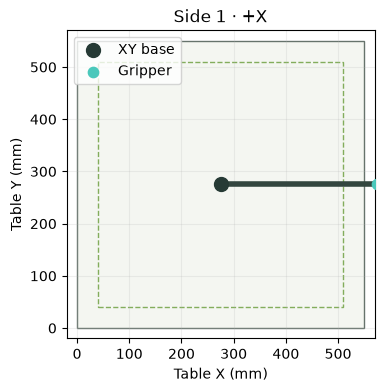

{'machine_xyz_mm': (235.0, 235.0, 470.0),
 'a_axis_deg': 0.0,
 'side': 1,
 'facing': '+X'}

In [ ]:
def run_full_cycle():
    logger.info("Cycle 1/3: home to machine origin (0, 0, max Z), facing +X")
    go_home()
    logger.info("Cycle 2/3: transport plate once from +Y to +X")
    transfer_plate(SOURCE_SLOT, DESTINATION_SLOT)
    logger.info("Cycle 3/3: return to machine home (0, 0, max Z)")
    robot.set_orientation(1)
    robot.move_machine_to(x=0.0, y=0.0, z=SAFE_Z_MM)
    final_pose = pose_summary()
    print("Full simulated cycle complete:", final_pose)
    show_pose()
    return final_pose


run_full_cycle()

In [12]:
robot.set_orientation(4)
robot.move_to(x=0.0, y=0.0, z=SAFE_Z_MM)

In [11]:
robot.move_to(x=470/2, y=470/2, z=200)

In [18]:
robot.transport(1, 2, (100, 100, 0), (100, 100, 0))